In [1]:
import geopandas as gpd
import pygris
import matplotlib.pyplot as plt

walk_area = gpd.read_file("data/walk_area.gpkg")
parks = gpd.read_file("data/parks_utm.gpkg")
boundary = gpd.read_file("data/boundary.gpkg").to_crs(walk_area.crs)

In [2]:
blocks = pygris.blocks(state="IL", county="Lake", year=2020, cache=True)
blocks = blocks.to_crs(walk_area.crs)
blocks[["GEOID20", "POP20"]].head()

Using FIPS code '17' for input 'IL'
Using FIPS code '097' for input 'Lake'


,GEOID20,POP20
1209,170978660002178,0
1210,170978644082028,48
1211,170978644101009,97
1212,170978608112010,0
1213,170978636011011,435


In [3]:
points = blocks.representative_point()
in_village = points.within(boundary.union_all())
blocks = blocks[in_village].copy()
print(len(blocks), "blocks")
blocks["POP20"].sum()

133 blocks


np.int64(5621)

In [4]:
blocks["served"] = blocks.representative_point().within(walk_area.union_all())
served_pop = blocks.loc[blocks["served"], "POP20"].sum()
total_pop = blocks["POP20"].sum()
print(served_pop, "of", total_pop, "residents")
round(served_pop / total_pop * 100, 1)

2663 of 5621 residents


np.float64(47.4)

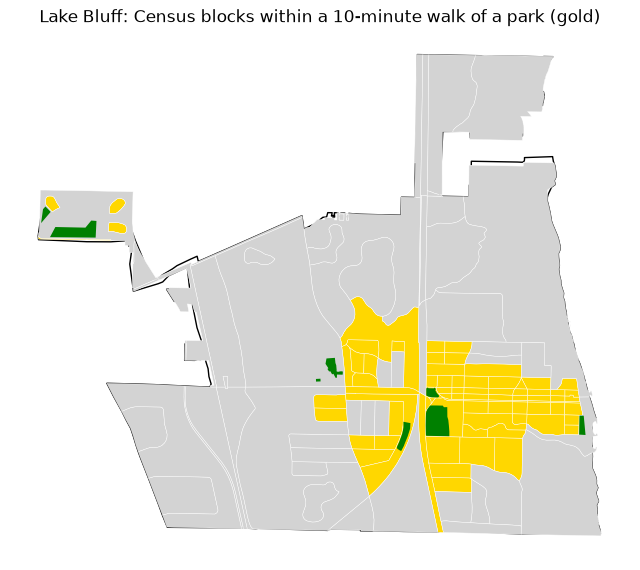

In [5]:
ax = boundary.plot(color="none", edgecolor="black", figsize=(8, 8))
blocks[blocks["served"]].plot(ax=ax, color="gold", edgecolor="white", linewidth=0.3)
blocks[~blocks["served"]].plot(ax=ax, color="lightgrey", edgecolor="white", linewidth=0.3)
parks.plot(ax=ax, color="green")
ax.set_title("Lake Bluff: Census blocks within a 10-minute walk of a park (gold)")
ax.set_axis_off()
plt.savefig("outputs/park_access_map.png", dpi=300, bbox_inches="tight")

In [6]:
blocks.to_file("data/blocks_access.gpkg")
blocks[["GEOID20", "POP20", "served"]].to_csv("outputs/block_access.csv", index=False)